# Báo cáo project

### Họ và tên: Trần Quốc Việt
### MSV: B24DCCE291

# 0. Giới thiệu bài toán và bộ dữ liệu - ONLINE SHOPPERS PURCHASING INTENTION PREDICTION

## 1. Giới thiệu bài toán (Problem Definition)

### 1.1. Bối cảnh bài toán (Background)

Trong lĩnh vực thương mại điện tử (E-commerce), việc hiểu hành vi truy cập và dự đoán khả năng mua hàng của khách hàng có vai trò quan trọng trong việc tối ưu trải nghiệm người dùng và hỗ trợ các hoạt động kinh doanh.

Thông qua dữ liệu hành vi như số trang đã xem, thời gian truy cập, tỷ lệ thoát trang và thông tin về loại khách hàng, Machine Learning có thể được sử dụng để nhận diện các đặc điểm liên quan đến quyết định mua hàng.

### 1.2. Mục tiêu bài toán (Objective)

Dự án xây dựng mô hình Machine Learning nhằm **dự đoán một phiên truy cập website thương mại điện tử có dẫn đến giao dịch mua hàng hay không**, dựa trên các đặc trưng về hành vi và ngữ cảnh truy cập.

Đây là bài toán **Supervised Learning – Binary Classification**, trong đó:

- Input (X): Các đặc trưng hành vi và thông tin phiên truy cập.
- Target (y): `Revenue`, biểu thị kết quả mua hàng.
- `Revenue = 0`: Phiên truy cập không phát sinh giao dịch mua hàng.
- `Revenue = 1`: Phiên truy cập có phát sinh giao dịch mua hàng.

### 1.3. Hướng tiếp cận (Approach)

Dự án được triển khai theo quy trình Machine Learning end-to-end:

1. Data Understanding & Data Quality Assessment.
2. Exploratory Data Analysis (EDA).
3. Data Preprocessing & Feature Engineering.
4. Model Training & Hyperparameter Tuning.
5. Model Evaluation & Comparison.
6. Ablation Study & Error Analysis.

- Mô hình dự kiến thử nghiệm gồm Logistic Regression
- Mô hình phát triển sau: Support Vector Machine (SVM), Random Forest và XGBoost.

Mục tiêu không chỉ đạt độ chính xác cao mà còn đánh giá khả năng nhận diện lớp khách hàng mua hàng, phân tích ảnh hưởng của các đặc trưng và lựa chọn mô hình phù hợp.

---

## 2. Giới thiệu bộ dữ liệu (Dataset Description)

### 2.1. Nguồn dữ liệu (Data Source)

Dự án sử dụng bộ dữ liệu **Online Shoppers Purchasing Intention Dataset** được công bố trên UCI Machine Learning Repository vào năm 2018.

- Tên dataset: Online Shoppers Purchasing Intention Dataset
- Nguồn: [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)
- Tác giả: C. Sakar và Y. Kastro
- Năm công bố: 2018
- Số lượng bản ghi: 12.330
- Số lượng đặc trưng đầu vào: 17
- Biến mục tiêu: Revenue
- Dạng dữ liệu: Tabular Data
- Bài toán: Binary Classification

Dataset chứa thông tin của 12.330 phiên truy cập website thương mại điện tử trong khoảng thời gian một năm. Dữ liệu được xây dựng để mỗi phiên thuộc về một người dùng khác nhau, nhằm hạn chế sự phụ thuộc vào một nhóm khách hàng hoặc chiến dịch cụ thể.

### 2.2. Cấu trúc dữ liệu (Data Structure)

Bộ dữ liệu gồm 18 cột, trong đó có 17 đặc trưng đầu vào và 1 biến mục tiêu.

Các đặc trưng được chia thành những nhóm chính:

| Nhóm đặc trưng | Các thuộc tính | Ý nghĩa |
|---|---|---|
| Hành vi truy cập | Administrative, Informational, ProductRelated | Số trang truy cập theo từng loại |
| Thời gian truy cập | Administrative_Duration, Informational_Duration, ProductRelated_Duration | Tổng thời gian trên từng nhóm trang |
| Web Analytics | BounceRates, ExitRates, PageValues | Các chỉ số phân tích hành vi website |
| Thời điểm truy cập | Month, SpecialDay, Weekend | Thời gian và ngữ cảnh truy cập |
| Thông tin truy cập | OperatingSystems, Browser, Region, TrafficType | Thiết bị, khu vực và nguồn truy cập |
| Loại khách hàng | VisitorType | Khách mới, khách quay lại hoặc nhóm khác |
| Biến mục tiêu | Revenue | Có phát sinh giao dịch mua hàng hay không |

### 2.3. Phân phối biến mục tiêu (Target Distribution)

Bộ dữ liệu có sự mất cân bằng giữa hai lớp:

| Revenue | Số lượng | Tỷ lệ |
|---|---:|---:|
| 0 – Không mua hàng | 10.422 | 84,53% |
| 1 – Có mua hàng | 1.908 | 15,47% |

Tỷ lệ giữa lớp không mua và có mua xấp xỉ 5,46:1, cho thấy bài toán có hiện tượng **Class Imbalance**.

Điều này đặt ra thách thức trong quá trình huấn luyện và đánh giá mô hình. Một mô hình luôn dự đoán khách hàng không mua vẫn có thể đạt Accuracy khoảng 84,53% nhưng không nhận diện được bất kỳ phiên mua hàng nào.

Do đó, ngoài Accuracy, dự án sẽ sử dụng thêm Precision, Recall, F1-score, ROC-AUC và Average Precision (AP) để đánh giá hiệu quả mô hình.

### 2.4. Đặc điểm và thách thức của dữ liệu

Bộ dữ liệu có một số đặc điểm đáng chú ý:

- Không có Missing Values trong dữ liệu gốc.
- Một số biến số có phân phối lệch phải mạnh và xuất hiện các giá trị cực trị lớn.
- Nhiều đặc trưng có tỷ lệ giá trị bằng 0 cao.
- Một số thuộc tính được mã hóa bằng số nguyên nhưng thực chất là biến phân loại.
- Dữ liệu có hiện tượng mất cân bằng giữa hai lớp Revenue.
- `PageValues` có liên hệ với giá trị chuyển đổi và cần được kiểm tra về khả năng rò rỉ thông tin (Data Leakage).

Những đặc điểm này cần được phân tích trong EDA để lựa chọn phương pháp tiền xử lý, thiết kế đặc trưng và mô hình Machine Learning phù hợp.

### 2.5. Phạm vi nghiên cứu

Dự án tập trung vào việc phân tích dữ liệu dạng bảng và dự đoán nhãn mua hàng từ các đặc trưng phiên truy cập đã được cung cấp.

Do dataset không chứa chuỗi sự kiện và timestamp chi tiết, kết quả thực nghiệm chưa đủ để khẳng định mô hình có thể dự đoán chính xác ý định mua hàng tại mọi thời điểm trong một phiên truy cập thực tế.

Dự án sẽ ưu tiên đánh giá mô hình trên dữ liệu độc lập và thực hiện các thí nghiệm so sánh nhằm kiểm chứng hiệu quả của preprocessing, feature engineering và lựa chọn thuật toán.

---

**Tài liệu tham khảo**

Sakar, C., & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository.

DOI: https://doi.org/10.24432/C5F88Q



# 1.Data ingestion + Data Understanding & EDA
## Data overview

In [113]:
import pandas as pd
df = pd.read_csv('D:\End_contest\online_shoppers_intention.csv')
df.head(20)

<>:2: SyntaxWarning: "\E" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\E"? A raw string is also an option.
<>:2: SyntaxWarning: "\E" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\E"? A raw string is also an option.
C:\Users\Admin\AppData\Local\Temp\ipykernel_20184\1628684823.py:2: SyntaxWarning: "\E" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\E"? A raw string is also an option.
  df = pd.read_csv('D:\End_contest\online_shoppers_intention.csv')


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
5,0,0.0,0,0.0,19,154.216667,0.015789,0.024561,0.0,0.0,Feb,2,2,1,3,Returning_Visitor,False,False
6,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
7,1,0.0,0,0.0,0,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,2,1,5,Returning_Visitor,True,False
8,0,0.0,0,0.0,2,37.000000,0.000000,0.100000,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False
9,0,0.0,0,0.0,3,738.000000,0.000000,0.022222,0.0,0.4,Feb,2,4,1,2,Returning_Visitor,False,False


### Nhận xét các nhãn đáng chú ý:
- BounceRates: Chỉ số tỷ lệ người truy cập vào một trang rồi rời website mà không tiếp tục tương tác, được tổng hợp cho phiên 
- ExitRates: Chỉ số tỷ lệ lượt xem kết thúc tại trang, được tổng hợp cho phiên
- PageValues: Chỉ số giá trị chuyển đổi được quy cho các trang đã truy cập, dựa trên dữ liệu giao dịch/mục tiêu
- ProductRelated: Số trang liên quan đến sản phẩm đã xem
- ProductRelated_Duration: Tổng thời gian xem các trang sản phẩm
- VisitorType: Phân loại khách truy cập web
- Month: Tháng truy cập web

In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split



In [115]:
# Chuẩn hóa nhãn thành 0 và 1 
df["Revenue"] = (
    df["Revenue"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"true": 1, "false": 0, "1": 1, "0": 0})
)

assert df["Revenue"].notna().all(), "Revenue có giá trị NaN"
df["Revenue"] = df["Revenue"].astype(int)

print("Dataset shape:", df.shape)
display(df.head())
# => phù hợp với bài toán phân loại nhị phân, thuận tiện khi huấn luyện và đánh giá, dễ phân tích dữ liệu, đồng nhất dữ liệu

Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,0


In [116]:
# Tổng quan dữ liệu:
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

print("\nTên các cột:")
print(df.columns.tolist())

print("\nKiểu dữ liệu:")
print(df.dtypes)

print("\nThông tin dataset:")
df.info()

print("\nThống kê mô tả:")
display(df.describe(include="all").T)


Số dòng: 12330
Số cột: 18

Tên các cột:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Kiểu dữ liệu:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                      int64
dtype: object

Thông ti

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


### Nhận xét:
- Dataset gồm 12.330 phiên truy cập với 17 features và 1 target, không có missing values.

- Dữ liệu tồn tại ba đặc điểm đáng chú ý: 
+ Phân phối các biến thời gian lệch phải. Do có mean > median nhiều lần trong các feature
+ Chênh lệch lớn giữa các lớp Revenue (84,53% so với 15,47%) => mất cân bằng dữ liệu => ảnh hưởng đén phân phối và train dữ liệu 
+ Do dữ liệu có nhiều số 0 => kéo mean xuống => các giá trị max lớn hơn rất nhiều so với mean => ko tự xác định là các outliers => không xử dụng IQR

- Một số biến số nguyên thực chất là categorical, cần mã hóa phù hợp. Các feature như PageValues, ProductRelated_Duration và ExitRates mã hóa bằng One-Hot encoding

=> Thử Log Transformation và Scaling cho các mô hình nhạy với thang đo; sử dụng Stratified Split, đánh giá bằng nhiều metrics và kiểm chứng các phương pháp xử lý class imbalance.

# 2. Data quality

In [117]:
#Phân loại các features 

#Biến mục tiêu, cột muốn dự đoán hoặc phân loại => tránh rò rỉ dữ liệu (không đưa vào tập train)
target_col = "Revenue"

# Biến số, dữ liệu dạng số nguyên => xử lý bằng thống kê, chuẩn hóa, hoặc trực quan hóa để hiểu phân phối 
numerical_cols = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

#Biến phân loại, dữ liệu dạng nhãn => được mã hóa (encoding) thành số để đưa vào mô hình. => tránh mô hình sẽ học nhầm quan hệ số học => có thể áp dụng One-hot encoding/ Target encoding
categorical_cols = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

#Danh sách thứ tự các tháng => Sắp xếp theo thời gian (Các tháng có mối liên hệ thời gian với nhau không phải rời rạc) => giúp giữ dòng chảy thời gian
month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "June",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

In [118]:
# Kiểm tra missing data => không phải xử lí giá trị null
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": df.isna().mean() * 100
})

display(missing.sort_values(
    "Missing Count",
    ascending=False
))

,Missing Count,Missing %
Administrative,0,0.0
Administrative_Duration,0,0.0
Informational,0,0.0
Informational_Duration,0,0.0
ProductRelated,0,0.0
ProductRelated_Duration,0,0.0
BounceRates,0,0.0
ExitRates,0,0.0
PageValues,0,0.0
SpecialDay,0,0.0


In [119]:
#Kiểm tra dòng trùng lặp => tránh vấn đề leakage data
print("Số dòng trùng:", df.duplicated().sum())

duplicate_rows = df[df.duplicated(keep=False)]

display(duplicate_rows.head(20))

print(
    df.loc[df.duplicated(), "Revenue"]
    .value_counts()
)

Số dòng trùng: 125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,0
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,0
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,0
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,0
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,0
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,0
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,0
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,0
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,0
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,0


Revenue
0    125
Name: count, dtype: int64


### Nhận xét:
- Có 125 dòng trùng lặp hoàn toàn, chiếm ~1.01% tổng số phiên (125/12,330 dòng).
- **Vấn đề**: 
- Nếu giữ nguyên, khi chia Train/Test sẽ có khoảng 96 mẫu trùng lặp chéo giữa 2 tập, dẫn đến hiện tượng rò rỉ dữ liệu (Data Leakage). Vì 1 bản sao rơi vào tập train và 1 bản sao rơi vào tập test => mô hình sẽ học thuộc dữ liệu. 
- Hơn nữa dữ liệu ban đầu vốn đã bị mất cân bằng lớp ($84.5%$ không mua vs $15.5%$ mua). Nếu giữ lại $125$ dòng trùng lặp này (toàn bộ đều là lớp Không mua), bạn đang vô tình "bơm thêm mẫu rác" vào lớp chiếm đa số, khiến mô hình bị thiên lệch (bias) nặng hơn và càng lười dự đoán lớp Mua hàng.
- **Xử lí**: 
- Loại bỏ 125 dòng trùng này trước khi chia tập huấn luyện/kiểm thử để đảm bảo tính khách quan cho mô hình.


In [120]:
# Kiểm tra các giá trị không hợp lệ

# Các cột đếm trang và thời gian không được có giá trị âm
non_negative_cols = [
    "Administrative", "Informational",
    "ProductRelated",
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration"
]

for col in non_negative_cols:
    print(col, "giá trị âm:",
          (df[col] < 0).sum())

# Kiểm tra các chỉ số dạng tỷ lệ (các feature có giải giá trị nằm trong 1 khoảng nhất định)
for col in ["BounceRates", "ExitRates"]:
    invalid = (~df[col].between(0, 1)).sum()
    print(col, "ngoài [0, 1]:", invalid)

# Kiểm tra giá trị vô hạn
print(
    "Số giá trị vô hạn:",
    np.isinf(df[numerical_cols].to_numpy()).sum()
)

Administrative giá trị âm: 0
Informational giá trị âm: 0
ProductRelated giá trị âm: 0
Administrative_Duration giá trị âm: 0
Informational_Duration giá trị âm: 0
ProductRelated_Duration giá trị âm: 0
BounceRates ngoài [0, 1]: 0
ExitRates ngoài [0, 1]: 0
Số giá trị vô hạn: 0


### Nhận xét:
- Tập dataset không có dữ liệu không hợp lệ nên không phải xử lí dữ liệu không hợp lệ
- Nếu tồn tại dữ liệu không hợp lệ => mô hình sẽ có thể học sai, dự đoán sai 

# Chia tập dữ liệu trước khi phân tích

In [121]:
# Chia tập train lấy 80% từ dataset
# Chia tập test lấy 20% từ dataset
df_train, df_test = train_test_split(
    df,
    test_size=0.2,
    stratify=df["Revenue"],
    random_state=42
)

df_train = df_train.copy()
df_test = df_test.copy()

# Dùng df_eda cho tất cả phân tích tiếp theo
df_eda = df_train.copy()

print("Training:", df_train.shape)
print("Testing:", df_test.shape)

Training: (9864, 18)
Testing: (2466, 18)


# 3. EDA 1 — Phân phối nhãn Revenue (Class Imbalance)
## 3.1. Thống kê số lượng hai lớp

In [122]:
# Số mẫu và tỷ lệ mỗi lớp
counts = df_eda["Revenue"].value_counts().sort_index()
print("Số lượng mẫu mỗi lớp:")
print(counts)
print("\nTỷ lệ % mỗi lớp:")
print((counts / len(df_eda) * 100).round(2))

Số lượng mẫu mỗi lớp:
Revenue
0    8338
1    1526
Name: count, dtype: int64

Tỷ lệ % mỗi lớp:
Revenue
0    84.53
1    15.47
Name: count, dtype: float64


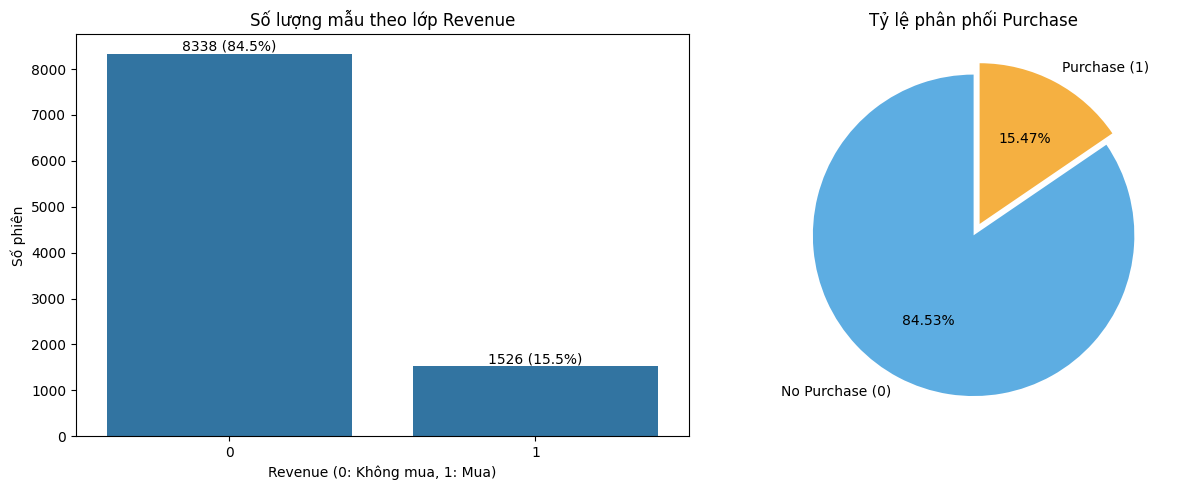

In [123]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Countplot
sns.countplot(
    data=df_eda,
    x="Revenue",
    order=[0, 1],
    ax=axes[0]
)
axes[0].set_title("Số lượng mẫu theo lớp Revenue")
axes[0].set_xlabel("Revenue (0: Không mua, 1: Mua)")
axes[0].set_ylabel("Số phiên")
for p in axes[0].patches:
    axes[0].annotate(
        f"{int(p.get_height())} ({p.get_height()/len(df_eda)*100:.1f}%)",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

# Pie chart
axes[1].pie(
    counts,
    labels=["No Purchase (0)", "Purchase (1)"],
    autopct="%1.2f%%",
    startangle=90,
    colors=["#5dade2", "#f5b041"],
    explode=(0, 0.08)
)
axes[1].set_title("Tỷ lệ phân phối Purchase")

plt.tight_layout()
plt.show()

### Nhận xét:
- **Vấn đề**:
  + Lớp 0 (No Purchase - Không mua hàng): Chiếm đa số áp đảo với ~84.5% (~8,338 phiên trong tập train).
  + Lớp 1 (Purchase - Có mua hàng): Chỉ chiếm ~15.5% (~1,526 phiên trong tập train).
  + Tỷ lệ mất cân bằng tự nhiên xấp xỉ **5.5 : 1** — đặc trưng điển hình của tỷ lệ chuyển đổi E-commerce.
- **Cách xử lí**:
  + **Không dùng Accuracy**: Dự đoán toàn bộ là 0 vẫn đạt 84.5% Accuracy nhưng hoàn toàn vô dụng.
  + **Metrics đánh giá bắt buộc**: **PR-AUC (Precision-Recall AUC)**, **F1-Score lớp 1**, và **ROC-AUC**.
  - **Kỹ thuật xử lý**
  **Dùng phân tầng (`StratifiedKFold`)**
  - Khi chia dữ liệu train/test, đảm bảo tỷ lệ lớp 0 và lớp 1 được giữ nguyên. Tránh tình trạng tập test toàn 0 hoặc quá ít 1. 

  **Cấu hình `class_weight='balanced`**
  - Với Logistic Regression, Random Forest, SVM: dùng class_weight='balanced'.
  - Tăng trọng số cho lớp hiếm, giúp mô hình chú ý nhiều hơn đến lớp 1.

  **Tối ưu ngưỡng xác suất (Threshold Tuning)**
  - Mặc định, mô hình phân loại dùng ngưỡng 0.5.
  - Với dữ liệu mất cân bằng, có thể giảm ngưỡng xuống (ví dụ 0.3) để tăng Recall cho lớp 1
  - Chọn ngưỡng tối ưu dựa trên PR-AUC hoặc F1-Score.


# 4. EDA 2 — Phân tích biến số & Biến đổi phân phối 
## 4.1. Thống kê mô tả các biến số

In [124]:
stats = df_eda[numerical_cols].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T

stats["skewness"] = df_eda[numerical_cols].skew()
stats["zero_ratio_%"] = (df_eda[numerical_cols] == 0).mean() * 100

display(stats.round(2))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max,skewness,zero_ratio_%
Administrative,9864.0,2.32,3.32,0.0,0.00,1.00,4.00,7.00,9.00,14.00,27.00,1.97,46.71
Administrative_Duration,9864.0,81.24,179.61,0.0,0.00,8.00,93.00,223.64,348.53,868.38,3398.75,5.68,47.71
Informational,9864.0,0.50,1.28,0.0,0.00,0.00,0.00,2.00,3.00,6.00,24.00,4.14,78.54
Informational_Duration,9864.0,34.59,141.43,0.0,0.00,0.00,0.00,72.00,194.93,720.30,2549.38,7.70,80.47
ProductRelated,9864.0,31.45,43.62,0.0,7.00,18.00,38.00,74.00,108.00,210.37,705.00,4.37,0.27
ProductRelated_Duration,9864.0,1186.55,1909.25,0.0,182.57,600.54,1474.51,2859.66,4232.52,8588.70,63973.52,8.01,6.20
BounceRates,9864.0,0.02,0.05,0.0,0.00,0.00,0.02,0.06,0.20,0.20,0.20,2.92,44.84
ExitRates,9864.0,0.04,0.05,0.0,0.01,0.03,0.05,0.10,0.20,0.20,0.20,2.13,0.62
PageValues,9864.0,5.94,18.56,0.0,0.00,0.00,0.00,19.11,39.16,85.20,361.76,6.19,77.77
SpecialDay,9864.0,0.06,0.20,0.0,0.00,0.00,0.00,0.20,0.60,1.00,1.00,3.26,89.72


### Nhận xét:
- Lệch phải cực đoan (Skewness rất cao: 4.0 – 8.0): Ví dụ: $50%$ khách chỉ xem trang sản phẩm dưới 10 phút (600s), nhưng giá trị cao nhất lên tới gần 18 tiếng (63,973s). 
=> Linear Regression sẽ bị kéo lệch nghiệm.
=> Áp dụng log1p để nén dải giá trị => giảm đạo hàm giật cục => học nhanh hội tụ ổn định hơn
=> Áp dụng Winsorization (Capping ở phân vị 99% ) thay vì xóa dòng

- Tràn ngập số 0 (Zero-Inflation: 45% – 90% là số 0): Gần $80%$ khách không vào trang tin tức (Informational = 0) và không phát sinh giá trị trang (PageValues = 0). Gần $90%$ phiên diễn ra vào ngày thường (SpecialDay = 0). 
=> Không dùng quy tắc IQR để loại bỏ Outliers vì có thể loại giá trị hợp lệ
=> có thể tạo thêm cờ nhị phân (Binary Indicator): 
- Is_PageValue_Zero = (PageValues == 0) 
- Has_Informational = (Informational > 0) 
- => Giúp cây quyết định thực hiện nhát cắt nhị phân ngay tại Node đầu tiên để tách nhóm "không tương tác" ra khỏi nhóm "có tương tác", tiết kiệm độ sâu của cây và tăng tốc độ suy luận.


- PageValues là biến quyết định (Key Driver): 
- Feature có liên quan tiền bạc (Revenue Attribution): Trong Google Analytics, một trang web chỉ được cộng điểm Page Value khi trong lịch sử đã có người ghé qua trang đó rồi thực hiện mua hàng thành công. => Một trang có Page Value > 0 đồng nghĩa với việc: Trang này nằm trên "con đường dẫn đến chốt đơn.


In [125]:
# Đếm trên tập train df_eda (hoặc thay bằng df nếu muốn đếm trên toàn bộ dataset)
count_false = ((df_eda["PageValues"] > 0) & (df_eda["Revenue"] == 0)).sum()
total_pv_gt_0 = (df_eda["PageValues"] > 0).sum()

print(f"Số lượng phiên có PageValues > 0 nhưng Revenue = False: {count_false:,} phiên")
print(f"Tỷ lệ chiếm: {count_false / total_pv_gt_0 * 100:.2f}% trong tổng số phiên có PageValues > 0")


Số lượng phiên có PageValues > 0 nhưng Revenue = False: 953 phiên
Tỷ lệ chiếm: 43.46% trong tổng số phiên có PageValues > 0


### Nhận xét:
- Trong thực tế khách hàng đã bấm vào các trang sản phẩm bán chạy, thậm chí đã bấm vào trang giỏ hàng. Trang đó có PageValues > 0. Nhưng ở bước cuối cùng, họ không hoàn tất thanh toán (do thấy phí ship cao, đổi ý, mạng lỗi, hoặc lưu lại để hôm sau mua). Kết quả phiên ghi nhận Revenue = False.
- Hiện tượng bỏ rơi giỏ hàng => không thể chỉ phụ thuộc vào mỗi feature PageValues được

=== BẢNG THỐNG KÊ TỶ LỆ MUA HÀNG THEO TỪNG KHOẢNG PAGEVALUES ===


,PageValue_Range,Tong_So_Phien,So_Don_Mua,Ty_Le_Mua_Hang_Percent
0,0 (Bằng 0),7671,286,3.73
1,"(0, 10]",739,279,37.75
2,"(10, 25]",669,372,55.61
3,"(25, 50]",450,317,70.44
4,"(50, 100]",271,215,79.34
5,> 100 (Cực cao),64,57,89.06


C:\Users\Admin\AppData\Local\Temp\ipykernel_20184\802840695.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


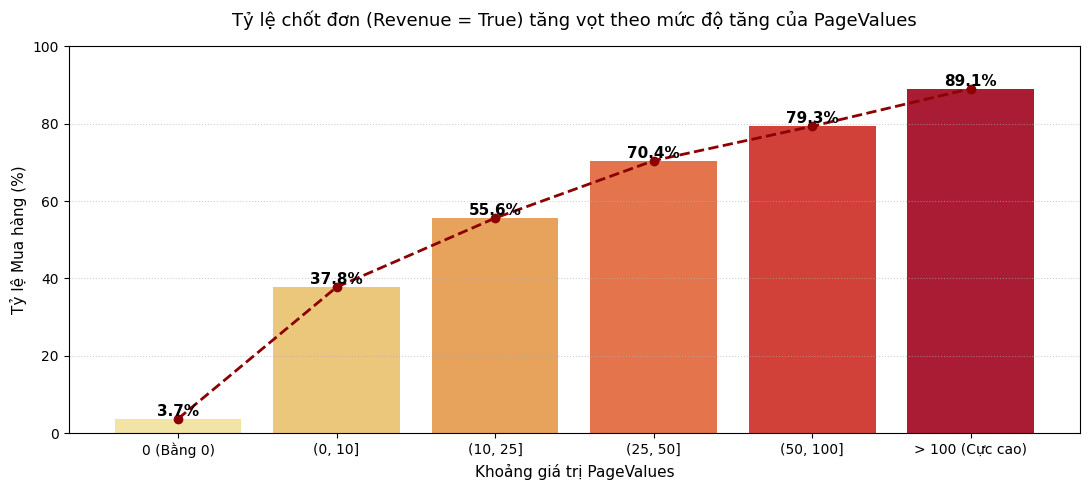

In [126]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tạo bản sao và chia các khoảng PageValues thực tế
df_pv = df_eda.copy()

# Định nghĩa các mốc giá trị PageValues từ 0 đến cực đại
bins = [-0.001, 0, 10, 25, 50, 100, np.inf]
labels = ["0 (Bằng 0)", "(0, 10]", "(10, 25]", "(25, 50]", "(50, 100]", "> 100 (Cực cao)"]

df_pv["PageValue_Range"] = pd.cut(df_pv["PageValues"], bins=bins, labels=labels)

# 2. Thống kê số lượng phiên và tỷ lệ phần trăm Revenue = True (Mua hàng)
pv_analysis = df_pv.groupby("PageValue_Range", observed=True).agg(
    Tong_So_Phien=("Revenue", "count"),
    So_Don_Mua=("Revenue", "sum"),
    Ty_Le_Mua_Hang_Percent=("Revenue", lambda x: x.mean() * 100)
).reset_index()

print("=== BẢNG THỐNG KÊ TỶ LỆ MUA HÀNG THEO TỪNG KHOẢNG PAGEVALUES ===")
display(pv_analysis.round(2))

# 3. Vẽ biểu đồ trực quan hóa xu hướng tăng trưởng
plt.figure(figsize=(11, 5))
ax = sns.barplot(
    data=pv_analysis,
    x="PageValue_Range",
    y="Ty_Le_Mua_Hang_Percent",
    palette="YlOrRd"
)

# Thêm đường xu hướng (Trendline) kết nối các mốc
plt.plot(
    range(len(pv_analysis)),
    pv_analysis["Ty_Le_Mua_Hang_Percent"],
    color="darkred",
    marker="o",
    linewidth=2,
    linestyle="--"
)

# Ghi chú phần trăm cụ thể trên từng cột
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{height:.1f}%",
        (p.get_x() + p.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title("Tỷ lệ chốt đơn (Revenue = True) tăng vọt theo mức độ tăng của PageValues", fontsize=13, pad=15)
plt.xlabel("Khoảng giá trị PageValues", fontsize=11)
plt.ylabel("Tỷ lệ Mua hàng (%)", fontsize=11)
plt.ylim(0, 100)
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


### Nhận xét:
- PageValues càng cao thì tỉ lệ chốt đơn được càng cao => cho thấy PageValues ảnh hưởng chủ lực tới nhãn
- Vẫn xuất hiện trường hợp PageValues = 0 nhưng Revenue = 1 => có thể do hiện tượng khách bấm mua ngay từ quảng cáo nên Google Analytics chưa kịp ghi nhận và cập nhật giá trị PageValues

## 4.2. Kiểm tra Biến đổi Log (Log Transformation) cho các biến lệch mạnh
Do các biến thời gian và trang bị lệch phải cực đoan (Right-Skewed) và Zero-Inflation, chúng ta kiểm tra hiệu quả của phép biến đổi `np.log1p` trên 4 biến quan trọng nhất.

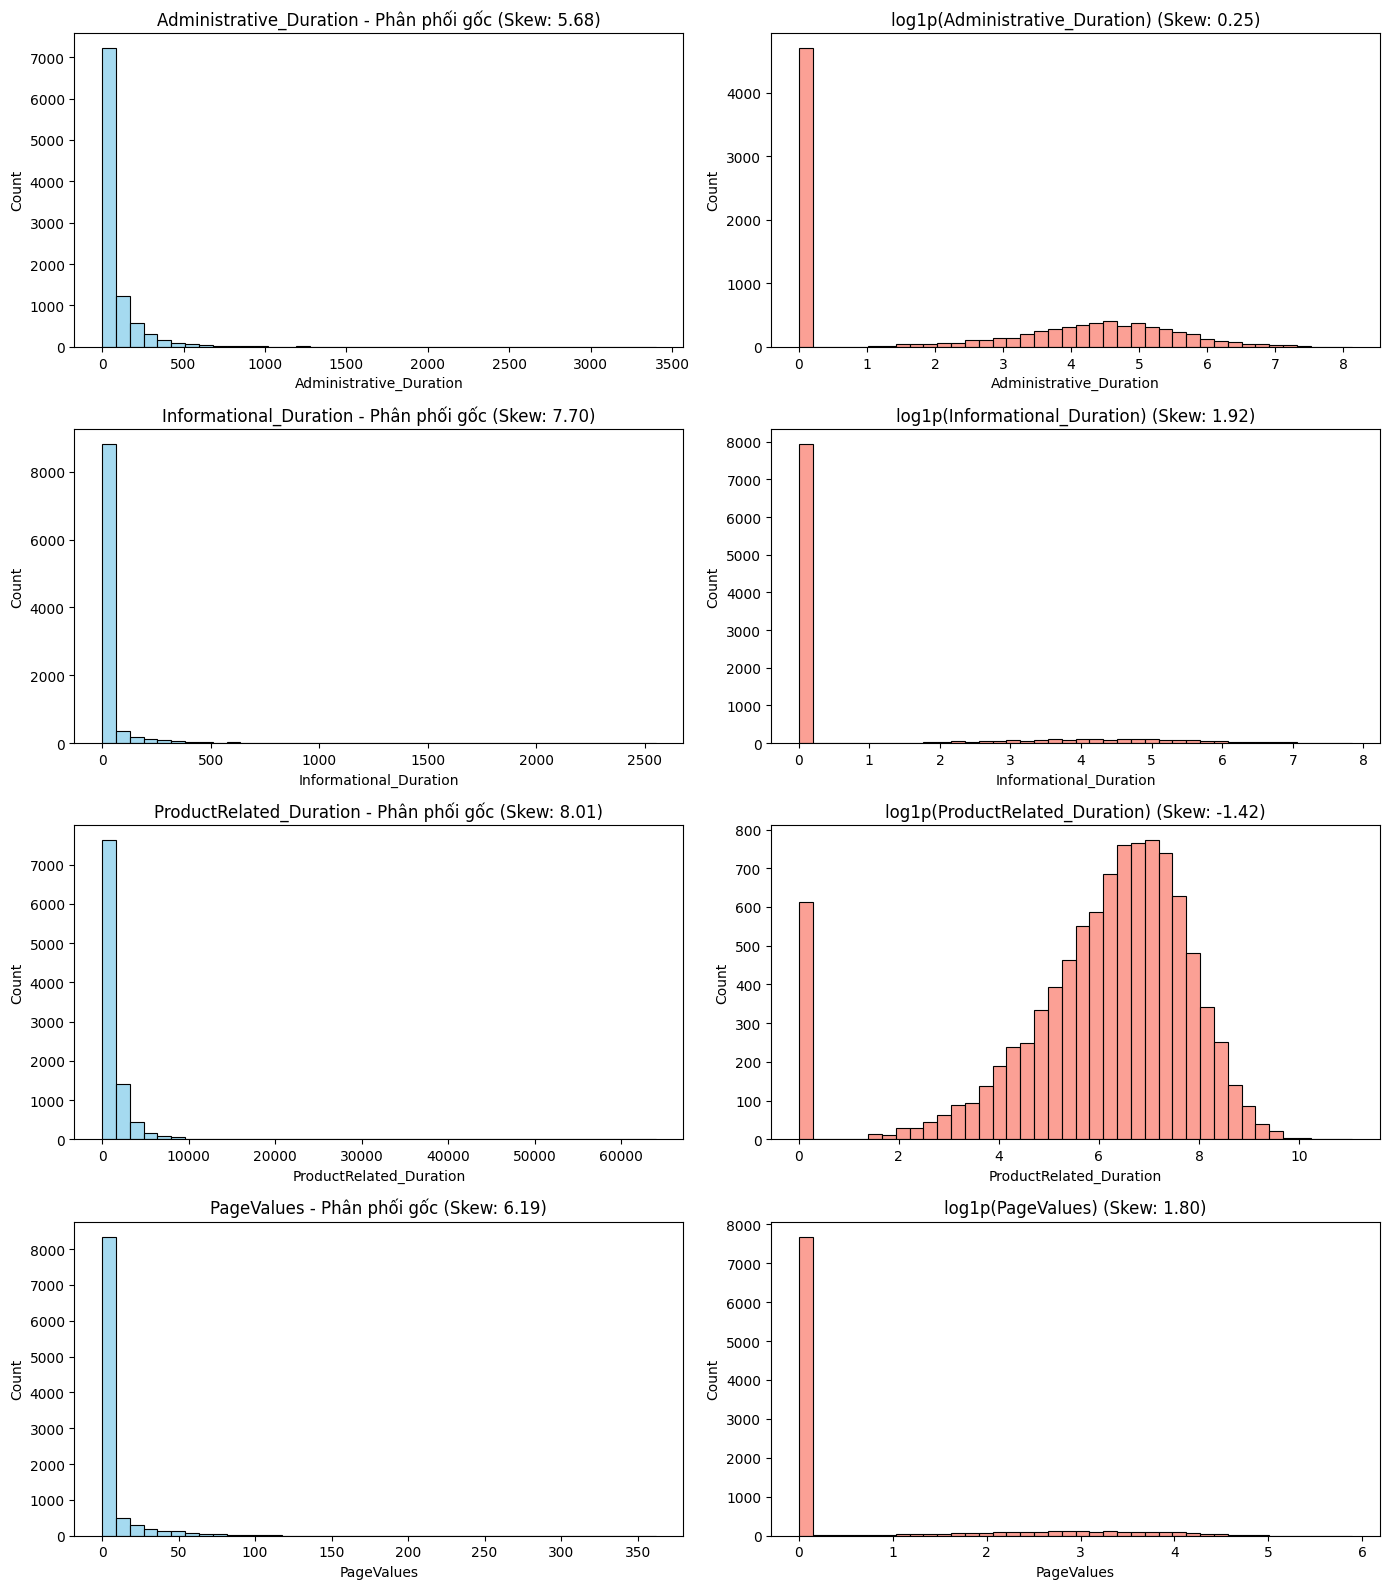

In [127]:
cols_to_log = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration",
    "PageValues"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for i, col in enumerate(cols_to_log):
    # Phân phối gốc
    sns.histplot(
        df_eda[col],
        bins=40,
        ax=axes[i, 0],
        color="skyblue"
    )
    axes[i, 0].set_title(f"{col} - Phân phối gốc (Skew: {df_eda[col].skew():.2f})")
    
    # Sau khi Log1p
    log_vals = np.log1p(df_eda[col])
    sns.histplot(
        log_vals,
        bins=40,
        ax=axes[i, 1],
        color="salmon"
    )
    axes[i, 1].set_title(f"log1p({col}) (Skew: {log_vals.skew():.2f})")

plt.tight_layout()
plt.show()

### Nhận xét:
- Các bảng trực quan hiện tượng Zero - Inflation xuất hiện ở cả với Informational_Duration & Administrative_Duration, PageValues, ProductRelated_Duration
- Phân phối gốc Lệch phải cực đoan (Right-Skewed nặng) với Skewness từ $5.68$ đến $8.01$. - Phân phối sau khi log1p: Trừ cột số 0, toàn bộ phần dữ liệu $>0$ phía sau đã được "duỗi thẳng" và uốn cong thành phân phối chuẩn hình chuông (Gaussian-like) rất đẹp mắt.

**Nếu không chuẩn hóa:**
- Mô hình linear Regression nhầm tưởng Duration = 0, 0.1, 1, 2 là biến liên tục đơn thuần là thời gian xem it hơn => sai vì Duration=0 => là tín hiệu khách hàng ko muốn mua khác với Duration>0
- Trọng số bị kéo lệch => dữ liệu đầu vào chủ yếu = 0 => mô hình linear học chủ yếu từ nhóm 0 này mà ko 
- Bùng nổ gradient ở 1 số điểm, feature 

- **Xử lí**
=> Vì Log1p chỉ giải quyết được cái đuôi dài phía sau chứ không xóa được cột số 0, => giải pháp chuẩn công nghiệp là: Tạo bộ đôi đặc trưng (Hurdle Model):
1. Cờ nhị phân: "Gánh" toàn bộ cột 0 cao chọc trời
df["Is_Zero"] = (df["Duration"] == 0).astype(int) => để xử lý dứt điểm cột cao tại 0 (gán một mức điểm phạt riêng cho nhóm không vào trang) - có tương tác hay ko, nếu có mức độ là bao nhiêu 
2. Biến liên tục: "Gánh" toàn bộ phần hình chuông phía sau
df["Log_Duration"] = np.log1p(df["Duration"]) => để đo lường độ dài thời gian cho những người thực sự có tương tác.
3. Kết hợp cả `np.log1p` kết hợp `RobustScaler` hoặc `StandardScaler` khi xử lí với mô hình Linear Regression => giảm bùng nổ đạo hàm

# 5. EDA 3 — Mối quan hệ giữa Biến số (Numerical Features) và Revenue
## 5.1. So sánh Mean và Median theo Revenue

In [128]:
summary = df_eda.groupby("Revenue")[numerical_cols].agg(["mean", "median"]).T
display(summary.round(3))

Revenue                                0         1
Administrative          mean       2.115     3.425
                        median     0.000     2.000
Administrative_Duration mean      73.616   122.902
                        median     0.000    53.125
Informational           mean       0.452     0.795
                        median     0.000     0.000
Informational_Duration  mean      30.436    57.288
                        median     0.000     0.000
ProductRelated          mean      28.550    47.315
                        median    16.000    29.000
ProductRelated_Duration mean    1067.322  1837.981
                        median   511.333  1120.850
BounceRates             mean       0.026     0.005
                        median     0.004     0.000
ExitRates               mean       0.048     0.019
                        median     0.029     0.016
PageValues              mean       1.948    27.780
                        median     0.000    17.323
SpecialDay              mean       0.070     0.021
                        median     0.000     0.000

### Nhận xét:
- Hành vi tương tác: Khách mua hàng xem nhiều trang sản phẩm hơn và dành nhiều thời gian để đọc các trang thông tin liên quan thì sẽ có xu hướng mua hàng lớn hơn 
- Tỷ lệ thoát trang: Nhóm mua có BounceRates và ExitRates thấp hơn đáng kể so với nhóm không mua, cho thấy mối liên hệ giữa mức độ tương tác và khả năng mua hàng.
- PageValues: Là đặc trưng phân hóa hai nhóm rất rõ. Median tăng từ 0 lên 17,32; Mean nhóm mua cao hơn khoảng 14 lần.
- SpecialDay: Nhóm mua có giá trị SpecialDay trung bình thấp hơn nhóm không mua
- Phân phối: Các biến thời gian có Mean lớn hơn Median, cho thấy dấu hiệu phân phối lệch phải và xuất hiện giá trị cực lớn.
-> Các feature có mean> median

## 5.2. Histogram phân phối ProductRelated theo Revenue

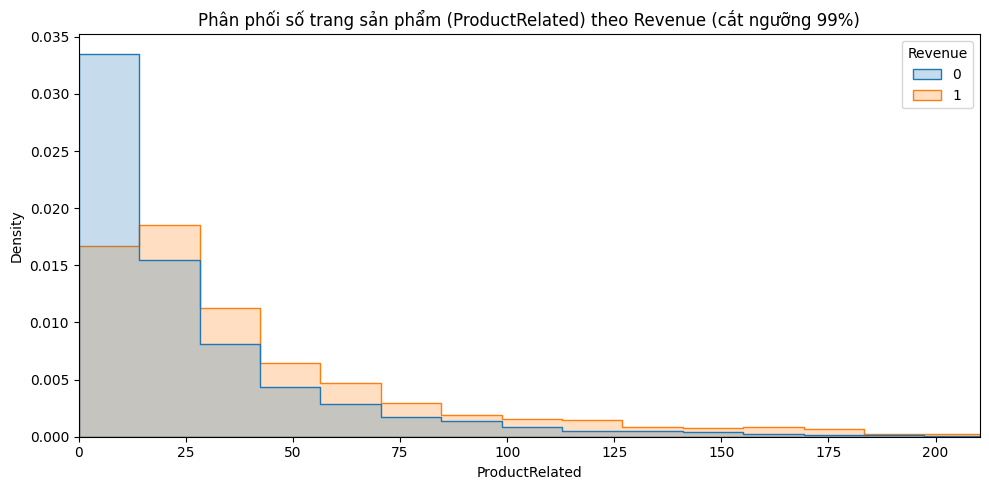

In [129]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_eda,
    x="ProductRelated",
    hue="Revenue",
    bins=50,
    stat="density",
    common_norm=False,
    element="step"
)
plt.xlim(0, df_eda["ProductRelated"].quantile(0.99))
plt.title("Phân phối số trang sản phẩm (ProductRelated) theo Revenue (cắt ngưỡng 99%)")
plt.tight_layout()
plt.show()

### Nhận xét:
1. Nhận xét dữ liệu
- Cả hai nhóm đều có phân phối lệch phải, phần lớn khách hàng xem ít trang sản phẩm.
- Nhóm không mua (Revenue = 0): Tập trung nhiều ở khoảng 0–15 trang sản phẩm.
- Nhóm mua (Revenue = 1): Có xu hướng xem nhiều trang sản phẩm hơn, phân phối trải rộng hơn.
- Hai nhóm vẫn chồng lấn đáng kể => chỉ dựa vào ProductRelated chưa đủ để phân loại chính xác.
2. Tác dụng:
- ProductRelated là feature tiềm năng giúp phân biệt khách mua và không mua.
- Kết hợp với ProductRelated_Duration để tạo feature ProductTimePerPage.

# 6. EDA 5 — Phân tích tương quan 
## 6.1. Spearman Correlation Heatmap

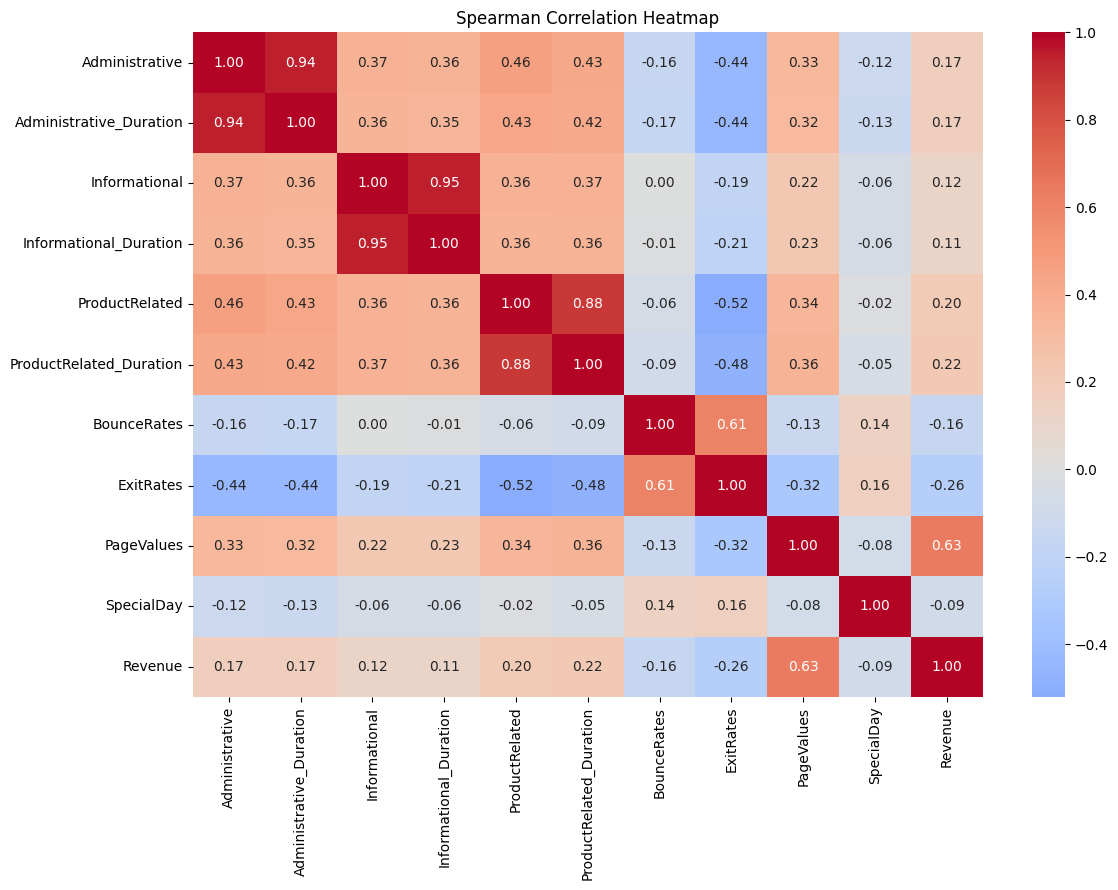

In [130]:
corr = df_eda[numerical_cols + ["Revenue"]].corr(method="spearman")

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

### Nhận xét:
- Tương quan dương rất mạnh: Administrative – Administrative_Duration (0.94), Informational – Informational_Duration (0.95), ProductRelated – ProductRelated_Duration (0.88) → Có khả năng dư thừa thông tin (Multicollinearity).
- Tương quan âm: ExitRates – ProductRelated (-0.52) → Phiên xem nhiều trang sản phẩm thường gắn với ExitRates thấp.
- BounceRates và ExitRates tương quan dương (0.61) → Hai chỉ số có mối liên hệ đáng kể.

=> Gộp Các feature có tương quan nhiều lại với nhau ở 1 mức độ nào nó

## 6.2. Xếp hạng mức độ tương quan với biến mục tiêu Revenue

Spearman Correlation với Revenue:
ExitRates                 -0.265
BounceRates               -0.158
SpecialDay                -0.090
Informational_Duration     0.114
Informational              0.116
Administrative_Duration    0.172
Administrative             0.173
ProductRelated             0.201
ProductRelated_Duration    0.220
PageValues                 0.632
Name: Revenue, dtype: float64


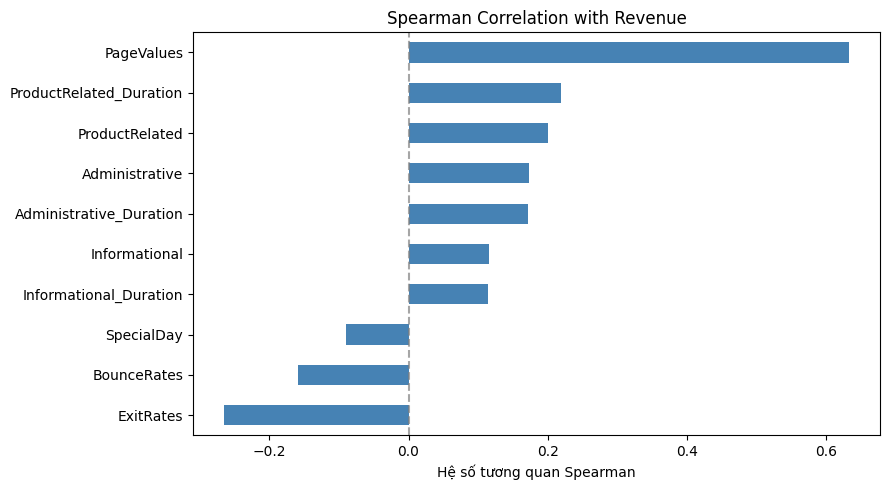

In [131]:
target_corr = (
    corr["Revenue"]
    .drop("Revenue")
    .sort_values()
)

print("Spearman Correlation với Revenue:")
print(target_corr.round(3))

plt.figure(figsize=(9, 5))
target_corr.plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)
plt.axvline(0, color="gray", linestyle="--", alpha=0.7)
plt.title("Spearman Correlation with Revenue")
plt.xlabel("Hệ số tương quan Spearman")
plt.tight_layout()
plt.show()

### Nhận xét:
1. Tương quan với Revenue
- PageValues (0.63): Có tương quan dương mạnh nhất với Revenue, là feature đáng chú ý nhất.
- ProductRelated_Duration (0.22), ProductRelated (0.20): Tương quan dương, cho thấy hành vi xem sản phẩm có liên hệ với khả năng mua hàng.
- ExitRates (-0.26), BounceRates (-0.16): Tương quan âm, phiên có tỷ lệ thoát cao thường ít mua hàng hơn.
- SpecialDay (-0.09): Tương quan âm rất yếu.
2. Ý nghĩa đối với Model Training
- Các feature có tương quan cao hơn với Revenue => có xu hướng quyết định nhiều đến tỉ lệ mua hàng => sẽ có trọng số cao hơn khi train model
- Các feature ko có nhiều tương quan có thể lược bỏ mà chú trọng đến các feature có tương quan cao hơn 

# 7. EDA 6 — Phân tích Dữ liệu cực trị & Hành vi bất thường (Extreme Outliers)
Phân tích top các phiên xem sản phẩm cực lâu để kiểm tra hành vi bất thường (treo máy, bot crawler).

In [132]:
display(
    df_eda.nlargest(10, "ProductRelated_Duration")[
        [
            "ProductRelated",
            "ProductRelated_Duration",
            "PageValues",
            "Revenue"
        ]
    ]
)

,ProductRelated,ProductRelated_Duration,PageValues,Revenue
8071,449,63973.52223,0.000000,0
5152,705,43171.23338,0.763829,0
9238,343,29970.46597,0.000000,0
8308,584,24844.15620,4.511100,0
7662,414,23888.81000,1.033757,0
6684,686,23342.08205,0.150650,0
5916,439,21857.04648,11.439233,0
8972,501,21672.24425,9.131387,1
10318,534,18504.12621,2.547956,1
8557,439,17550.58486,2.626909,1


### Nhận xét:
- **Phát hiện quan trọng**: 100% các phiên có thời gian cực lớn (>20,000s đến 63,000s, tức 5 đến 17 tiếng) đều có kết quả `Revenue = 0`.
- **Bản chất hành vi**: Đây là các phiên treo tab quên tắt hoặc bot/web crawler quét sản phẩm.
- **Xử lí** : Thay vì xóa dòng (dễ mất mẫu), ta áp dụng kỹ thuật **Winsorization / Capping** ở phân vị 99% để triệt tiêu ảnh hưởng của giá trị cực trị lên các mô hình nhạy cảm với scale. Và số trang xem lớn không đồng nghĩa với khả năng 

# 8. Feature Engineering & Phân tích đặc trưng mới tạo lập
Từ các phân tích dữ liệu: 
1. `TotalPages`: Tổng số trang truy cập (`Admin` + `Info` + `Product`).
2. `TotalDuration`: Tổng thời gian của phiên. 
3. `ProductTimePerPage`: Thời gian trung bình nghiền ngẫm mỗi trang sản phẩm.
4. `ProductPageRatio`: Tỷ trọng số trang sản phẩm trên tổng trang.
5. `ProductTimeRatio`: Tỷ trọng thời gian xem sản phẩm trên tổng thời gian.
6. `HasProductVisit`: Cờ nhị phân có vào xem sản phẩm hay không.
6. `Is_PageValue_Zero`: Kiểm tra xem PageValue có giá trị không
6. `Has_Informational`: Kiểm tra xem có truy cập thông tin ko

In [133]:
def add_engineered_features(data):
    df_fe = data.copy()

    # 1. Tổng số trang đã xem
    df_fe["TotalPages"] = (
        df_fe["Administrative"]
        + df_fe["Informational"]
        + df_fe["ProductRelated"]
    )

    # 2. Tổng thời gian truy cập các nhóm trang
    df_fe["TotalDuration"] = (
        df_fe["Administrative_Duration"]
        + df_fe["Informational_Duration"]
        + df_fe["ProductRelated_Duration"]
    )

    # 3. Thời gian trung bình trên mỗi trang sản phẩm
    df_fe["ProductTimePerPage"] = (
        df_fe["ProductRelated_Duration"]
        / df_fe["ProductRelated"].clip(lower=1)
    )

    # 4. Tỷ trọng trang sản phẩm
    df_fe["ProductPageRatio"] = (
        df_fe["ProductRelated"]
        / df_fe["TotalPages"].clip(lower=1)
    )

    # 5. Tỷ trọng thời gian xem sản phẩm
    df_fe["ProductTimeRatio"] = (
        df_fe["ProductRelated_Duration"]
        / df_fe["TotalDuration"].clip(lower=1)
    )

    # 6. Có truy cập trang sản phẩm không?
    df_fe["HasProductVisit"] = (
        df_fe["ProductRelated"] > 0
    ).astype(int)

    # 7. PageValues có bằng 0 không?
    df_fe["Is_PageValue_Zero"] = (
        df_fe["PageValues"] == 0
    ).astype(int)

    # 8. Có truy cập trang thông tin không?
    df_fe["Has_Informational"] = (
        df_fe["Informational"] > 0
    ).astype(int)

    return df_fe


# Khai báo danh sách engineered features
new_features = [
    "TotalPages",
    "TotalDuration",
    "ProductTimePerPage",
    "ProductPageRatio",
    "ProductTimeRatio",
    "HasProductVisit",
    "Is_PageValue_Zero",
    "Has_Informational"
]


df_fe = add_engineered_features(df_eda)

display(
    df_fe.groupby("Revenue")[new_features]
    .agg(["mean", "median"])
    .round(3)
)

TotalPages        TotalDuration           ProductTimePerPage          \
              mean median          mean    median               mean  median   
Revenue                                                                        
0           31.116   18.0      1171.374   587.375             36.749  27.421   
1           51.535   32.5      2018.171  1254.417             42.379  35.840   

        ProductPageRatio        ProductTimeRatio        HasProductVisit  \
                    mean median             mean median            mean   
Revenue                                                                   
0                  0.908  0.974            0.834  0.973           0.997   
1                  0.889  0.929            0.886  0.945           0.999   

               Is_PageValue_Zero        Has_Informational         
        median              mean median              mean median  
Revenue                                                           
0          1.0             0.886    1.0             0.194    0.0  
1          1.0             0.187    0.0             0.325    0.0

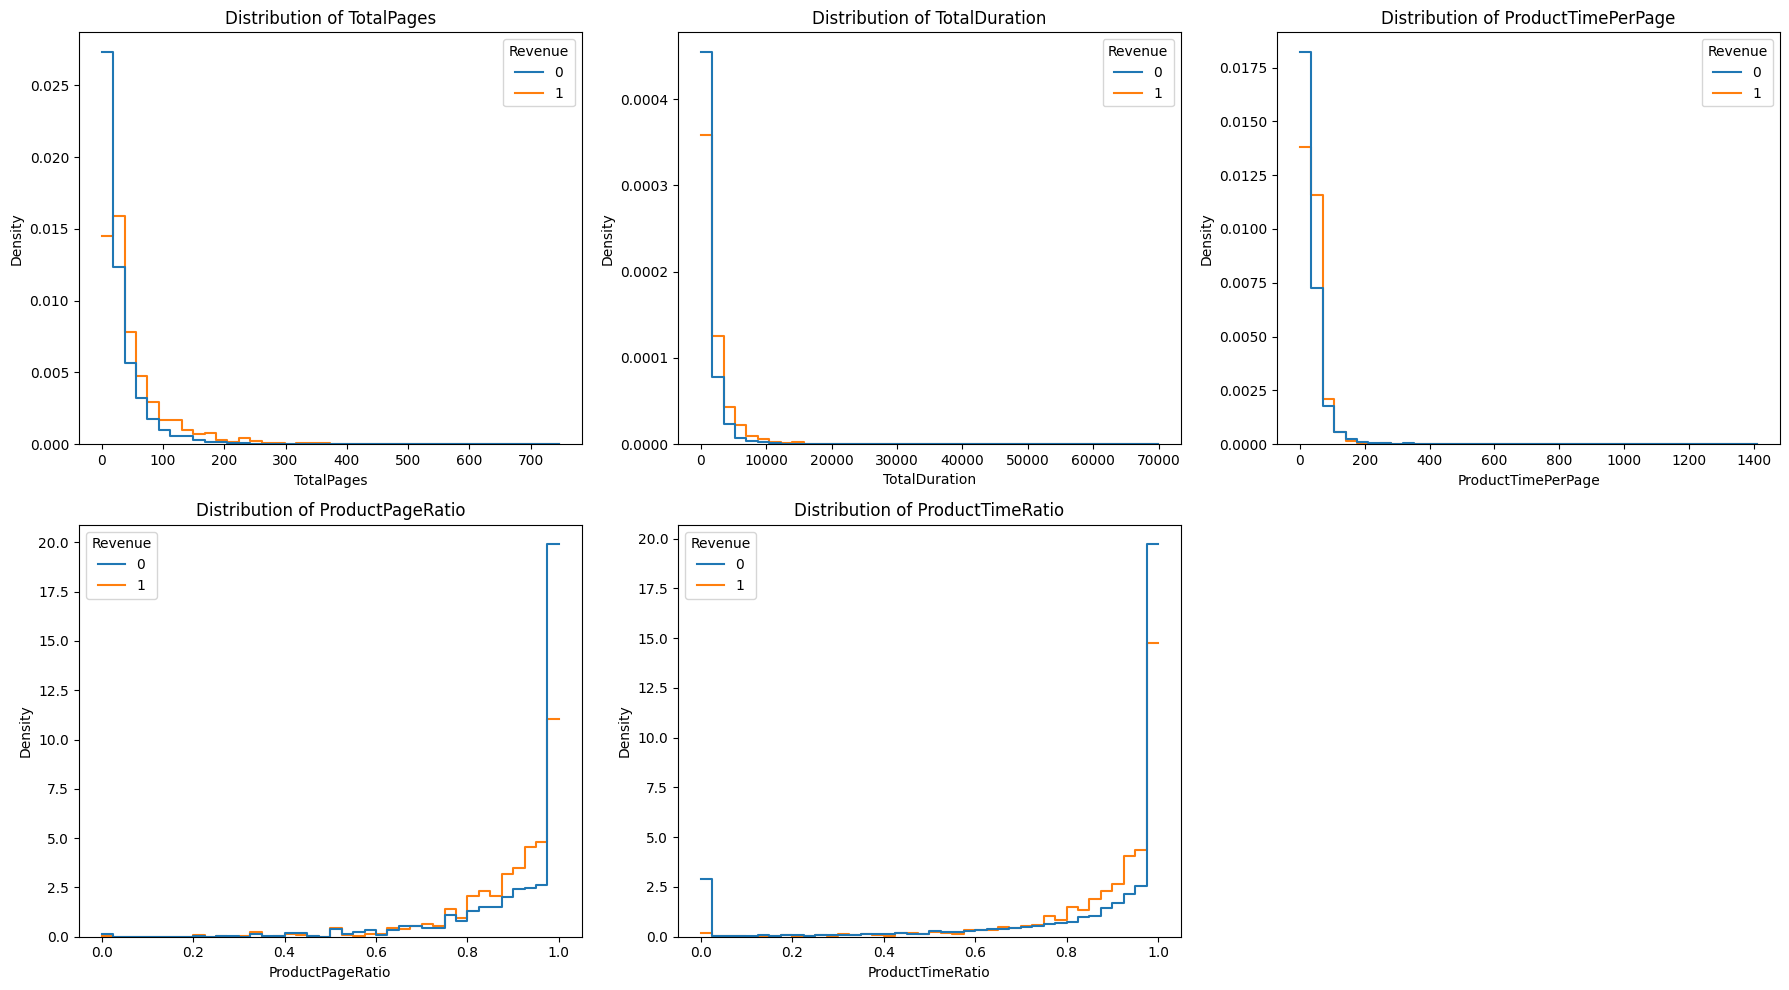

In [134]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

num_fe_cols = [
    "TotalPages",
    "TotalDuration",
    "ProductTimePerPage",
    "ProductPageRatio",
    "ProductTimeRatio"
]

# Sử dụng dữ liệu train đã Feature Engineering
plot_df = add_engineered_features(df_train)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(num_fe_cols):
    data_plot = plot_df.copy()

    # Log Transformation chỉ để trực quan hóa
    if col in ["TotalPages", "TotalDuration", "ProductTimePerPage"]:
        data_plot[col] = data_plot[col]
        xlabel = f"{col}"
    else:
        xlabel = col

    sns.histplot(
        data=data_plot,
        x=col,
        hue="Revenue",
        bins=40,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(xlabel)
    axes[i].set_ylabel("Density")

# Ẩn subplot thừa
for j in range(len(num_fe_cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

# Chia tập dữ liệu trước khi train 

In [136]:
# Áp dụng cùng công thức Feature Engineering
df_train, df_test = train_test_split(
    df,
    test_size = 0.2,
    stratify=df["Revenue"],
    random_state=42
)
df_train = add_engineered_features(df_train)
df_test = add_engineered_features(df_test)

print("Train:", df_train.shape)
print("Test:", df_test.shape)

print("\nCác features mới:")
display(df_train[new_features].head())

Train: (9864, 26)
Test: (2466, 26)

Các features mới:


,TotalPages,TotalDuration,ProductTimePerPage,ProductPageRatio,ProductTimeRatio,HasProductVisit,Is_PageValue_Zero,Has_Informational
4263,42,2078.005952,39.581057,0.809524,0.647619,1,0,0
5905,4,157.200000,39.300000,1.000000,1.000000,1,1,0
9434,4,42.000000,10.500000,1.000000,1.000000,1,1,0
3505,19,1543.566667,70.915686,0.894737,0.781027,1,0,0
2067,32,827.646212,25.863944,1.000000,1.000000,1,0,0


# Chuẩn bị X_train, X_test, y_train, y_test

In [137]:
# Tách features và target
X_train = df_train.drop(columns=["Revenue"])
y_train = df_train["Revenue"].astype(int)

X_test = df_test.drop(columns=["Revenue"])
y_test = df_test["Revenue"].astype(int)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nPhân phối nhãn Train:")
print(y_train.value_counts(normalize=True))

X_train: (9864, 25)
X_test: (2466, 25)

Phân phối nhãn Train:
Revenue
0    0.845296
1    0.154704
Name: proportion, dtype: float64


# Data preproccessing
### Tóm tắt các vấn đề:
- Không có missing value => chưa cần Imputation
- Các feature lệch phải => Thử log1p
- Numerical features khác thang đo => StandardScaler 
- Các mã categorical dạng số nguyên => One-hot encoding
- Class Imbalancing: Thử class_weight="balanced" khi train

In [138]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Các cột cần Log Transformation
log_cols = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration",
    "PageValues",

    # Engineered Features
    "TotalPages",
    "TotalDuration",
    "ProductTimePerPage",
    "ProductPageRatio",
    "ProductTimeRatio"
]

# Tách input và target
train_df = df_train.copy()
test_df = df_test.copy()

y_train = train_df["Revenue"].astype(int).to_numpy()
y_test = test_df["Revenue"].astype(int).to_numpy()

# 1. Numerical Features
all_numerical_cols = numerical_cols + new_features
train_num = train_df[all_numerical_cols].astype(float).copy()
test_num = test_df[all_numerical_cols].astype(float).copy()

# Log Transformation
train_num[log_cols] = np.log1p(train_num[log_cols])
test_num[log_cols] = np.log1p(test_num[log_cols])

# StandardScaler
mean_train = train_num.mean()
std_train = train_num.std(ddof=0).replace(0, 1)

train_num = (train_num - mean_train) / std_train
test_num = (test_num - mean_train) / std_train

# 2. Categorical Features - One-Hot Encoding
train_cat = pd.get_dummies(
    train_df[categorical_cols].astype(str),
    dtype=int
)
# pd.get_dummies() => Pandas sẽ tạo một cột mới cho mỗi giá trị xuất hiện.
# => Ép sang str để khẳng định là các dữ liệu nhãn, không phải giá trị số để tính toán + mọi category cùng KDL, ko lẫn Int/String, nhất quán train/test
# => dtype=int: tạo 0, 1

test_cat = pd.get_dummies(
    test_df[categorical_cols].astype(str),
    dtype=int
)

# Giữ các cột test giống train => sắp xếp và tạo lại các cột của test_cat sao cho giống hệt danh sách cột của train_cat.
test_cat = test_cat.reindex(
    columns=train_cat.columns,
    fill_value=0
)

# 3. Ghép các features
X_train_df = pd.concat([train_num, train_cat], axis=1)
X_test_df = pd.concat([test_num, test_cat], axis=1)

feature_names = X_train_df.columns

# Chuyển sang NumPy để tính toán
X_train = X_train_df.to_numpy(dtype=float)
X_test = X_test_df.to_numpy(dtype=float)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
# Thuật toán ML sử dụng nhiều numpy, nhanh hơn dataframe, nhiều thư viện yêu cầu numpy, đồng nhất KDL

Train: (9864, 83)
Test: (2466, 83)


In [139]:
print("Số features đầu vào:", X_train.shape[1])

print("\nEngineered features đã được thêm:")
for feature in new_features:
    print(feature, ": ", feature in feature_names)

print("\nKiểm tra NaN:", np.isnan(X_train).sum())
print("Kiểm tra Infinity:", np.isinf(X_train).sum())

assert X_train.shape[1] == X_test.shape[1]
assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()

Số features đầu vào: 83

Engineered features đã được thêm:
TotalPages :  True
TotalDuration :  True
ProductTimePerPage :  True
ProductPageRatio :  True
ProductTimeRatio :  True
HasProductVisit :  True
Is_PageValue_Zero :  True
Has_Informational :  True

Kiểm tra NaN: 0
Kiểm tra Infinity: 0


# Xây dựng Logistic Regression

In [ ]:
class LogisticRegressionScratch:

    def __init__(
        self,
        learning_rate=0.1,
        epochs=1500,          
        l2=0.01,              # Hệ số lambda
        class_weight=True,     # Dùng để xử lí dữ liệu mất cân bằng
        verbose=True
    ):
        self.lr = learning_rate
        self.epochs = epochs
        self.l2 = l2
        self.class_weight = class_weight
        self.loss_history = []

    # 1. Hàm Sigmoid
    def sigmoid(self, z):
        z = np.clip(z, -35, 35)
        return 1 / (1 + np.exp(-z))

    # 2. Huấn luyện mô hình
    def fit(self, X, y):

        n_samples, n_features = X.shape

        # Khởi tạo tham số
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []

        # Tính Class Weight
        if self.class_weight:
            n0 = np.sum(y == 0)
            n1 = np.sum(y == 1)

            weight0 = n_samples / (2 * n0)
            weight1 = n_samples / (2 * n1)

            sample_weight = np.where(
                y == 0, weight0, weight1
            )
            # Sai 1 mẫu class 1 sẽ bị phạt rất nặng => mô hình phải học cách nhận diện 1
        else:
            sample_weight = np.ones(n_samples)
            # Nếu mọi mẫu có ảnh hưởng như nhau => không thêm lớp nào cả

        # Gradient Descent
        for epoch in range(self.epochs):

            # Forward propagation
            z = X @ self.weights + self.bias
            y_prob = self.sigmoid(z)

            # Sai số có trọng số
            error = (y_prob - y) * sample_weight

            # Gradient + L2 Regularization
            dw = (
                (X.T @ error) / n_samples
                + self.l2 * self.weights
            )

            db = np.mean(error)

            # Cập nhật tham số
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

            # Theo dõi Loss
            if epoch % 100 == 0 or epoch == self.epochs - 1:

                z = X @ self.weights + self.bias

                # BCE ổn định số học + L2
                bce = np.mean(
                    sample_weight * (
                        np.logaddexp(0, z) - y * z
                    )
                )

                regularization = (
                    self.l2 / 2
                ) * np.sum(self.weights ** 2)

                loss = bce + regularization

                self.loss_history.append(loss)

                print(
                    f"Epoch {epoch:4d} | "
                    f"Loss: {loss:.5f}"
                )

        return self

    # 3. Dự đoán xác suất
    def predict_proba(self, X):
        z = X @ self.weights + self.bias
        return self.sigmoid(z)

    # 4. Dự đoán nhãn 0/1
    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)
        return (probabilities >= threshold).astype(int)

# Huấn luyện mô hình

In [141]:
model = LogisticRegressionScratch(
    learning_rate=0.1,
    epochs=1500,
    l2=0.01,
    class_weight=True
)

model.fit(X_train, y_train)

Epoch    0 | Loss: 0.64267
Epoch  100 | Loss: 0.38083
Epoch  200 | Loss: 0.37216
Epoch  300 | Loss: 0.36891
Epoch  400 | Loss: 0.36744
Epoch  500 | Loss: 0.36669
Epoch  600 | Loss: 0.36627
Epoch  700 | Loss: 0.36602
Epoch  800 | Loss: 0.36585
Epoch  900 | Loss: 0.36574
Epoch 1000 | Loss: 0.36565
Epoch 1100 | Loss: 0.36558
Epoch 1200 | Loss: 0.36553
Epoch 1300 | Loss: 0.36549
Epoch 1400 | Loss: 0.36545
Epoch 1499 | Loss: 0.36541


# Loss Curve


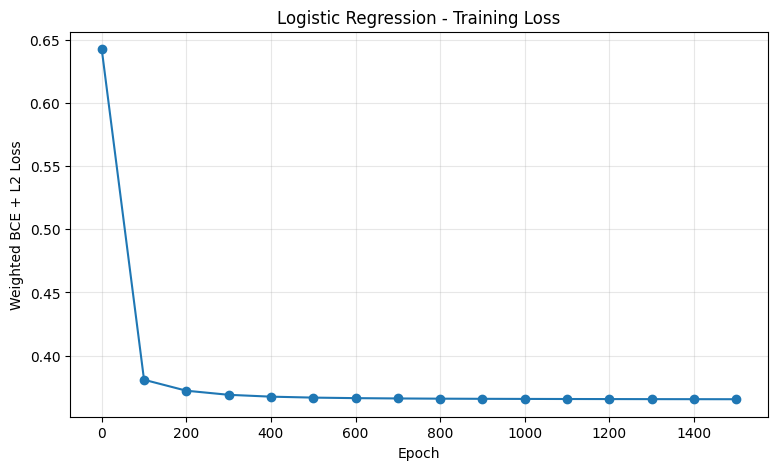

In [142]:
plt.figure(figsize=(9, 5))

epochs_recorded = list(range(0, model.epochs, 100))

if epochs_recorded[-1] != model.epochs - 1:
    epochs_recorded.append(model.epochs - 1)

plt.plot(
    epochs_recorded,
    model.loss_history,
    marker="o"
)

plt.title("Logistic Regression - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Weighted BCE + L2 Loss")
plt.grid(alpha=0.3)
plt.show()

### Nhận xét:
- Hàm loss giảm mạnh trong 200 epoche đầu => học được tốt trong 200 epoche đầu
- Bắt đầu từ epoche 200 => dường như không giảm

# Đánh giá mô hình

In [143]:
# Dự đoán trên test
y_prob = model.predict_proba(X_test)
y_pred = model.predict(X_test)

# Confusion Matrix
TP = np.sum((y_test == 1) & (y_pred == 1))
TN = np.sum((y_test == 0) & (y_pred == 0))
FP = np.sum((y_test == 0) & (y_pred == 1))
FN = np.sum((y_test == 1) & (y_pred == 0))

# Các metric cơ bản
accuracy = (TP + TN) / len(y_test)

precision = TP / (TP + FP) if TP + FP else 0
recall = TP / (TP + FN) if TP + FN else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

# ROC-AUC theo thứ hạng, có xử lý trường hợp đồng điểm
n_pos = np.sum(y_test == 1)
n_neg = np.sum(y_test == 0)

ranks = pd.Series(y_prob).rank(
    method="average"
).to_numpy()

roc_auc = (
    ranks[y_test == 1].sum()
    - n_pos * (n_pos + 1) / 2
) / (n_pos * n_neg)

# Average Precision từ Precision-Recall Curve
order = np.argsort(-y_prob, kind="mergesort")

sorted_y = y_test[order]
sorted_scores = y_prob[order]

cum_tp = np.cumsum(sorted_y)
cum_fp = np.cumsum(1 - sorted_y)

# Xét các ngưỡng điểm dự đoán khác nhau
end_idx = np.flatnonzero(
    np.r_[sorted_scores[1:] != sorted_scores[:-1], True]
)

precision_curve = (
    cum_tp[end_idx] /
    (cum_tp[end_idx] + cum_fp[end_idx])
)

recall_curve = cum_tp[end_idx] / n_pos

ap = np.sum(
    np.diff(np.r_[0, recall_curve]) * precision_curve
)

print("=== CONFUSION MATRIX ===")
print(f"TN = {TN}, FP = {FP}")
print(f"FN = {FN}, TP = {TP}")

print("\n=== METRICS ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"AP:        {ap:.4f}")

=== CONFUSION MATRIX ===
TN = 1827, FP = 257
FN = 73, TP = 309

=== METRICS ===
Accuracy:  0.8662
Precision: 0.5459
Recall:    0.8089
F1-score:  0.6519
ROC-AUC:   0.9188
AP:        0.6631


### Nhaanj xet